# General relativity 5: Orbits and the precession of Mercury

*Learning path: general relativity, part 5 of 9.* [Index](README.md) · Previous: [Black holes](04-black-holes.ipynb) · Next: [Light](06-light.ipynb)

Planets follow geodesics of the Schwarzschild spacetime. Far from the Sun these are almost Newton's ellipses, but not
quite, and the difference was the first triumph of general relativity. You will learn

* how the effective potential describes orbits, in Newton's theory and in Einstein's,
* why there is an innermost stable circular orbit around a black hole,
* why orbits in general relativity do not close but trace rosettes,
* how to compute the 43 arcseconds per century of Mercury's perihelion precession.

## 1. The effective potential

For a particle with angular momentum $L$ per unit mass, the Schwarzschild geodesic equations reduce to one equation
for the radius, like a ball rolling in a potential:

$$\left(\frac{dr}{d\tau}\right)^2 + V(r) = E^2, \qquad V(r) = \left(1 - \frac{r_s}{r}\right)\left(1 + \frac{L^2}{r^2}\right)$$

Multiplying out, $V = 1 - \dfrac{r_s}{r} + \dfrac{L^2}{r^2} - \dfrac{r_s L^2}{r^3}$. The first three terms are Newton's:
gravity pulling in, and the centrifugal barrier $L^2/r^2$ pushing out. The last term is new, and it wins at small $r$.
Here $V$ is plotted against $r$ (in units of $r_s$, so $r_s = 1$) for several values of $L$:

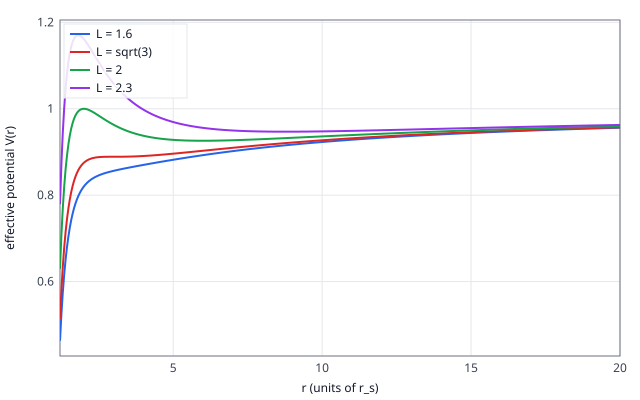

In [1]:
r_s = 1;
v1 = plot((1-r_s/r)*(1+1.6^2/r^2), r, 1.2, 20);
v2 = plot((1-r_s/r)*(1+3/r^2), r, 1.2, 20);
v3 = plot((1-r_s/r)*(1+2^2/r^2), r, 1.2, 20);
v4 = plot((1-r_s/r)*(1+2.3^2/r^2), r, 1.2, 20);
labels(legend(show(v1, v2, v3, v4), "L = 1.6", "L = sqrt(3)", "L = 2", "L = 2.3"), "r (units of r_s)", "effective potential V(r)")

A circular orbit sits at a minimum of $V$. For large $L$ (the top curves) there is a minimum, and a maximum closer in.
As $L$ decreases they merge, at $L^2 = 3r_s^2$, at radius $r = 3r_s$: the **innermost stable circular orbit** (ISCO) [7].
Closer in, nothing can orbit stably; matter spirals into the black hole. The inner edge of the glowing accretion disc
around a black hole sits at the ISCO. In Newton's theory, by contrast, the barrier $L^2/r^2$ always wins at small $r$:

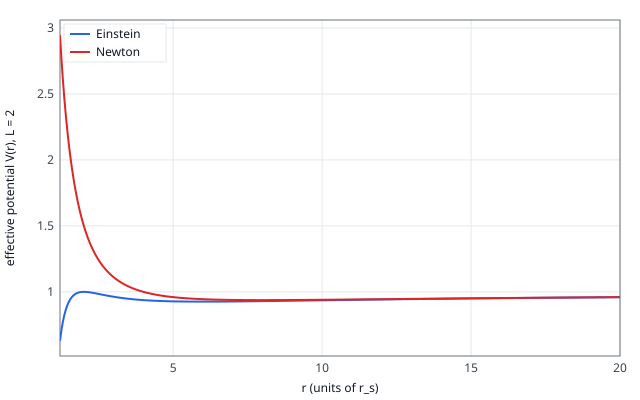

In [2]:
labels(legend(show(plot((1-r_s/r)*(1+2^2/r^2), r, 1.2, 20), plot(1 - r_s/r + 2^2/r^2, r, 1.2, 20)), "Einstein", "Newton"), "r (units of r_s)", "effective potential V(r), L = 2")

## 2. Rosettes: solving the orbit equation with `odeplot`

### From $r(t)$ to $u(\phi)$

To get the *shape* of an orbit we don't need to know where the planet is at each moment, only how far from the Sun it
is in each direction: $r$ as a function of the angle $\phi$. Two tricks make Newton's law simple [8]:

1. **Use the angle as the clock.** The angular momentum per unit mass, $h = r^2\,d\phi/dt$, is constant (Kepler's
   second law), so $d\phi/dt = h/r^2$ turns every time derivative into an angle derivative.
2. **Use $u = 1/r$ instead of $r$.** Then $dr/dt = -h\,u'$ and $d^2r/dt^2 = -h^2u^2u''$, where $'$ means $d/d\phi$.

Put both into Newton's radial equation $\ddot r - r\dot\phi^2 = -GM/r^2$ and divide by $-h^2u^2$:

$$u'' + u = \frac{GM}{h^2}$$

This is the **Binet equation**. It is the equation of a spring ($u'' = -u$) pushed by a constant force, so its solution
is an oscillation around $GM/h^2$:

$$u = \frac{GM}{h^2}\big(1 + e\cos\phi\big), \qquad\text{that is}\qquad r = \frac{p}{1 + e\cos\phi}, \quad p = \frac{h^2}{GM}$$

an ellipse with eccentricity $e$. Because $u$ goes through exactly one oscillation per turn ($\phi$ from 0 to $2\pi$),
the planet comes back to the same perihelion every time: the orbit closes.

### What is $p$?

$p$ is called the **semi-latus rectum** ("half the straight side" in Latin). It is the distance from the Sun to the
orbit measured at right angles to the long axis: put $\phi = 90°$ in $r = p/(1 + e\cos\phi)$ and you get $r = p$. Together
with $e$ it fixes the orbit: the closest distance (perihelion) is $r_p = p/(1+e)$ and the farthest (aphelion)
$r_a = p/(1-e)$. In terms of the semi-major axis $a = (r_p + r_a)/2$,

$$p = a(1 - e^2) = \frac{h^2}{GM}$$

so $p$ is also a measure of the angular momentum. Below, the orbit we will use: perihelion 20, aphelion 60, so
$a = 40$, $e = 0.5$ and $p = 30$. The Sun sits at a focus of the ellipse, not at its centre:

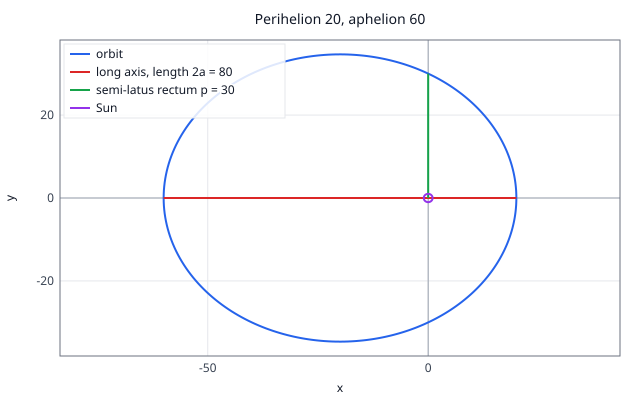

In [3]:
p = 30;
ecc = 0.5;
orbit = polarplot(p/(1+ecc*cos(phi)), phi, 0, 2*pi);
longaxis = parametric(t, 0, t, -60, 20);
latus = parametric(0, t, t, 0, p);
sun = parametric(cos(t), sin(t), t, 0, 2*pi);
title(legend(show(orbit, longaxis, latus, sun), "orbit", "long axis, length 2a = 80", "semi-latus rectum p = 30", "Sun"), "Perihelion 20, aphelion 60")

### Einstein's correction

In general relativity the same two tricks work on the Schwarzschild geodesics. Start from the energy equation of
section 1, $(dr/d\tau)^2 + V = E^2$ with $V = (1 - r_s/r)(1 + L^2/r^2)$. The angular momentum $L = r^2\,d\phi/d\tau$ plays
the role of $h$ (it is the same number, with proper time $\tau$ instead of $t$), so $dr/d\tau = -L\,u'$ and

$$L^2u'^2 + V(u) = E^2, \qquad V(u) = (1 - r_s u)(1 + L^2u^2)$$

Differentiate with respect to $\phi$: $2L^2u'u'' + V'(u)\,u' = 0$, so $u'' = -V'(u)/(2L^2)$. Galileo can do that step.
First Einstein's $V$, then Newton's, which is the same without the last term $-r_sL^2u^3$ (writing $h$ for $L$):

In [4]:
clear
V = (1 - r_s*u)*(1 + h^2*u^2);
expand(-deriv(V, u)/(2*h^2))

r_s/(2*h^2)+3*r_s*u^2/2-u

In [5]:
VN = 1 - r_s*u + h^2*u^2;
expand(-deriv(VN, u)/(2*h^2))

r_s/(2*h^2)-u

So the two orbit equations are

* Newton: $\;u'' = \dfrac{r_s}{2h^2} - u$
* Einstein: $\;u'' = \dfrac{r_s}{2h^2} - u + \tfrac{3}{2}r_s u^2$

With $c = 1$ the Schwarzschild radius is $r_s = 2GM$, so $r_s/(2h^2)$ is Newton's $GM/h^2$ and $\tfrac32 r_s u^2$ is $3GMu^2$.
The extra term comes from the $-r_sL^2/r^3$ in the potential, the same term that creates the ISCO in section 1.
Compared with $GM/h^2$ it is $3h^2u^2 = 3(v_\perp/c)^2$, three times the squared sideways speed in units of the speed of
light: about $10^{-7}$ for Mercury, but about 0.1 for the orbit below.

### Turning the equation into `odeplot` arguments

`odeplot` solves **first-order** equations, $dy/dt = f(t, y)$. A second-order equation becomes two first-order ones
when the derivative gets its own name. Call $w = u'$; then Newton's equation is

$$u' = w, \qquad w' = \frac{r_s}{2h^2} - u$$

Each argument of `odeplot([w, r_s/(2*h^2)-u], [u w], phi, [1/rp 0], 0, 10*pi, [cos(phi)/u sin(phi)/u])` has a job:

| argument | what it is | here |
|---|---|---|
| `[w, r_s/(2*h^2)-u]` | the right-hand sides: $u'$ and $w'$ | $u' = w$, $w' = r_s/(2h^2) - u$ |
| `[u w]` | the unknowns, in the same order | $u$, then $w = u'$ |
| `phi` | the independent variable, the "time" | the angle $\phi$ |
| `[1/rp 0]` | the unknowns at the start | at perihelion $u = 1/r_p$, and $u' = 0$ because $r$ is at its minimum |
| `0, 10*pi` | where to start and stop | five turns around the Sun |
| `[cos(phi)/u sin(phi)/u]` | what to draw, horizontal and vertical | $x = r\cos\phi$, $y = r\sin\phi$ with $r = 1/u$ |

The comma in `[w, r_s/(2*h^2)-u]` matters: inside brackets a space separates elements, so with a minus sign after a
space, `[w -u]` would be two elements, `w` and `-u`. A comma always works.

We work in units of $r_s$ ($r_s = 1$). Choosing $h = \sqrt{15}$ makes $p = h^2/GM = 2h^2/r_s = 30$, so starting at
$r_p = 20$ gives $e = 0.5$ and the orbit from the picture above. First, before drawing the orbit, look at $u$ itself:
the last argument `[phi u]` puts $\phi$ on the horizontal axis and $u$ on the vertical one:

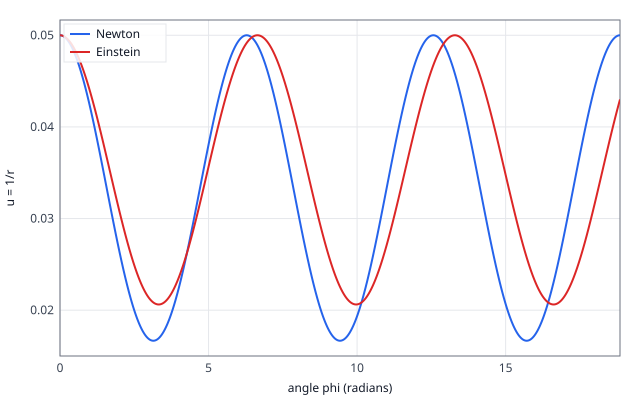

In [6]:
r_s = 1;
h = sqrt(15);
rp = 20;
un = odeplot([w, r_s/(2*h^2)-u], [u w], phi, [1/rp 0], 0, 6*pi, [phi u]);
ue = odeplot([w, r_s/(2*h^2)+1.5*r_s*u^2-u], [u w], phi, [1/rp 0], 0, 6*pi, [phi u]);
labels(legend(show(un, ue), "Newton", "Einstein"), "angle phi (radians)", "u = 1/r")

The peaks are perihelia ($u = 1/20$, closest to the Sun), the valleys aphelia. Newton's $u$ swings down to $1/60$ and
repeats exactly every $2\pi$, once per turn. Einstein's, started the same way, doesn't swing out quite as far (the
extra pull keeps it closer), and it takes a little longer than $2\pi$ to come back: each perihelion comes at a slightly
larger angle than the last. That lag is the precession. Now draw the orbits themselves, with $x = \cos\phi/u$ and $y = \sin\phi/u$:

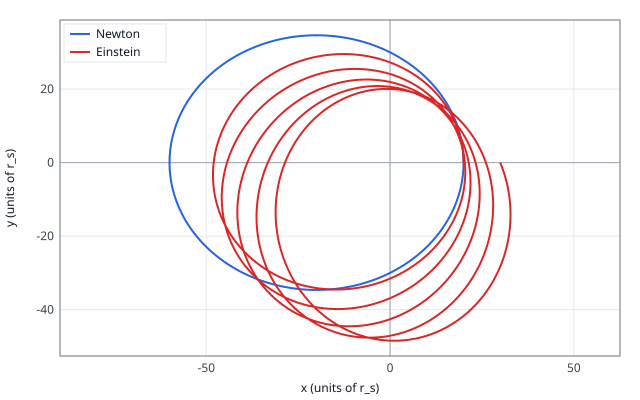

In [7]:
newton = odeplot([w, r_s/(2*h^2)-u], [u w], phi, [1/rp 0], 0, 10*pi, [cos(phi)/u sin(phi)/u]);
einstein = odeplot([w, r_s/(2*h^2)+1.5*r_s*u^2-u], [u w], phi, [1/rp 0], 0, 10*pi, [cos(phi)/u sin(phi)/u]);
labels(legend(show(newton, einstein), "Newton", "Einstein"), "x (units of r_s)", "y (units of r_s)")

The Newtonian ellipse retraces itself five times; the relativistic orbit turns a little further each time and traces
a rosette. The predicted shift per orbit is $\Delta\phi = 6\pi GM/\big(c^2 a(1 - e^2)\big) = 3\pi r_s/p$, with $p$ the
semi-latus rectum from above, here $30\,r_s$. In degrees:

In [8]:
p = 2*h^2/r_s
eval(3*pi*r_s/p*180/pi)

30
18.0

## 3. Straight from the metric

The orbit equation above came from the geodesic equations, but we can also integrate the full four-dimensional
geodesic equations directly. The planet starts at perihelion with $\dot\phi = L/r^2$ and $\dot t$ fixed so that
$g_{ab}\dot x^a\dot x^b = -1$. This time we draw the orbit on Flamm's paraboloid from part 4, the shape of space around
the mass:

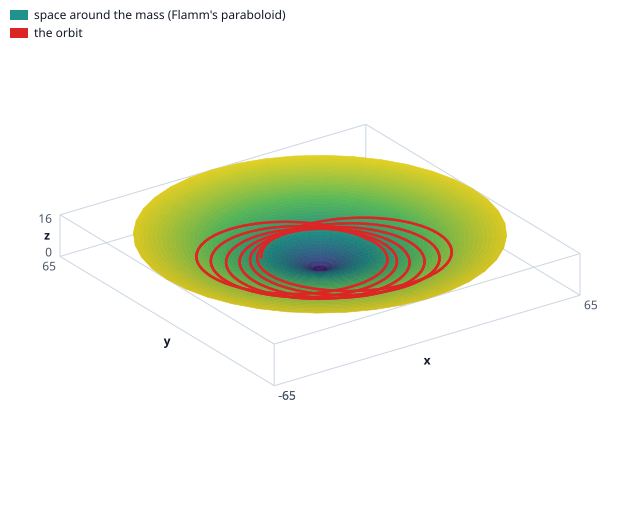

In [9]:
S = metric.generate(schwarzschild);
L = h;
ut = sqrt((1+L^2/rp^2)/(1-r_s/rp));
orbit = geodesic(S, [0 rp pi/2 0], [ut 0 0 L/rp^2], 11000, [r*cos(phi) r*sin(phi) 2*sqrt(r_s*(r-r_s))], 20000);
well = surface(r*cos(phi), r*sin(phi), 2*sqrt(r_s*(r-r_s)), r, 1, 65, phi, 0, 2*pi);
legend(show(well, orbit), "space around the mass (Flamm's paraboloid)", "the orbit")

The same rosette, now as a path on the curved surface.

## 4. Mercury

Now the real numbers, in SI units: the Sun's $GM$, the speed of light, and Mercury's semi-major axis, eccentricity and
orbital period in days [5].

In [10]:
clear
GM = 1.32712440018e20;
c = 299792458;
A = 5.7909e10;
ecc = 0.2056;
T = 87.969;
dphi = eval(6*pi*GM/(c^2*A*(1-ecc^2)))

5.018602644417367e-7

That is the shift per orbit, in radians. Mercury goes around $36525/T$ times per century. In arcseconds per century:

In [11]:
eval(dphi*(36525/T)*(180/pi)*3600)

42.980208088692486

**43 arcseconds per century.** Astronomers measure Mercury's perihelion advancing by about 574″ per century relative
to the stars, of which about 531″ is caused by the pull of the other planets [1]. Le Verrier found the anomaly in 1859 and
suggested an unseen planet inside Mercury's orbit, later called Vulcan [2]; the residual stayed a mystery for over half a
century. In November 1915 Einstein computed this number from his new theory [3], and
wrote to Paul Ehrenfest in January 1916 that "for a few days, I was beside myself with joyous excitement" [4].

> **A note on "retrograde".** Mercury's *retrograde* motion, when it seems to move backwards across the sky for a few
> weeks, is a different thing: a line-of-sight effect as Earth overtakes it or it overtakes Earth. Copernicus and
> Newton explain that fully.

The same effect is much larger in binary pulsars: for the Hulse–Taylor pulsar it is 4.2° per *year* [6].

## Summary

* Orbits follow from the effective potential $V = (1 - r_s/r)(1 + L^2/r^2)$; the extra $-r_sL^2/r^3$ is relativistic.
* No stable circular orbits exist inside $3r_s$ (the ISCO).
* Relativistic orbits precess by $6\pi GM/(c^2a(1-e^2))$ per orbit: 43″ per century for Mercury.

**Try it:** set `rp = 10` (perihelion at $10r_s$) in section 2. How fast does the rosette turn now?

Next: [Light](06-light.ipynb): bending, the photon sphere, and the shadow of a black hole.

## Sources

Numbers in square brackets in the text refer to this list.

1. G. M. Clemence, "The relativity effect in planetary motions", *Reviews of Modern Physics* **19**, 361–364 (1947): observed 574.10″ ± 0.65″ per century relative to the stars, planetary perturbations 531.54″, residual 42.56″ ± 0.94″. [doi:10.1103/RevModPhys.19.361](https://doi.org/10.1103/RevModPhys.19.361)
2. U. Le Verrier, "Lettre de M. Le Verrier à M. Faye sur la théorie de Mercure et sur le mouvement du périhélie de cette planète", *Comptes rendus de l'Académie des sciences* **49**, 379–383 (1859).
3. A. Einstein, "Erklärung der Perihelbewegung des Merkur aus der allgemeinen Relativitätstheorie", *Sitzungsberichte der Preußischen Akademie der Wissenschaften*, 831–839 (18 November 1915).
4. Einstein to Paul Ehrenfest, 17 January 1916, *The Collected Papers of Albert Einstein*, Vol. 8, Doc. 182, Princeton University Press (1998); quoted in A. Pais, *'Subtle is the Lord...'*, Oxford University Press (1982), p. 253.
5. NASA Goddard, *Mercury Fact Sheet*, [nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html](https://nssdc.gsfc.nasa.gov/planetary/factsheet/mercuryfact.html); solar GM from IAU 2015 Resolution B3, [arXiv:1510.07674](https://arxiv.org/abs/1510.07674).
6. J. M. Weisberg and Y. Huang, "Relativistic measurements from timing the binary pulsar PSR B1913+16", *Astrophysical Journal* **829**, 55 (2016): 4.226585° per year. [doi:10.3847/0004-637X/829/1/55](https://doi.org/10.3847/0004-637X/829/1/55)
7. C. W. Misner, K. S. Thorne and J. A. Wheeler, *Gravitation*, W. H. Freeman (1973). Chapter 25 (orbits in the Schwarzschild geometry).
8. H. Goldstein, C. Poole and J. Safko, *Classical Mechanics*, 3rd edition, Addison-Wesley (2002), section 3.7 (the differential equation for the orbit, in $u = 1/r$) and section 3.8 (the Kepler problem).